 User acquisition performance across cohorts, countries, and platforms

In [1]:
import pandas as pd

file = "data.xlsx"

df = pd.read_excel(file, sheet_name="Data - Part 1")


In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 2000)
pd.set_option('display.expand_frame_repr', False)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8162 entries, 0 to 8161
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   install_day     8162 non-null   datetime64[ns]
 1   platform        8162 non-null   object        
 2   campaign_name   8162 non-null   object        
 3   ad_name         8162 non-null   object        
 4   country         8160 non-null   object        
 5   country_tier    8162 non-null   object        
 6   bid_type        8162 non-null   object        
 7   Installs        5395 non-null   float64       
 8   pu_0_days       5395 non-null   float64       
 9   pu_14_days      5395 non-null   float64       
 10  pu_30_days      5395 non-null   float64       
 11  day2            5395 non-null   float64       
 12  day7            5395 non-null   float64       
 13  pu              5395 non-null   float64       
 14  net_revenue_0   5395 non-null   float64       
 15  net_

In [4]:
df.describe()

,install_day,Installs,pu_0_days,pu_14_days,pu_30_days,day2,day7,pu,net_revenue_0,net_revenue_14,net_revenue_30,net_revenue,impressions,clicks,spend
count,8162,5395.000000,5395.000000,5395.000000,5395.000000,5395.000000,5395.000000,5395.000000,5395.000000,5395.000000,5395.000000,5395.000000,8162.000000,8162.000000,8162.000000
mean,2020-02-15 19:07:39.593236992,10.638184,0.225023,0.303800,0.375904,4.369045,2.641891,0.428545,1.446371,3.187989,5.532482,10.984534,7788.097158,27.093237,48.477552
min,2020-01-15 00:00:00,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1.000000
25%,2020-01-31 00:00:00,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,505.250000,1.000000,3.060000
50%,2020-02-17 00:00:00,3.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1246.000000,4.000000,9.240000
75%,2020-03-03 00:00:00,11.000000,0.000000,0.000000,0.000000,4.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.690000,5538.500000,18.000000,35.875000
max,2020-03-16 00:00:00,503.000000,7.000000,7.000000,8.000000,245.000000,154.000000,8.000000,536.800000,2836.790000,2837.480000,12486.500000,244882.000000,1603.000000,1016.342857
std,NaN,22.734298,0.594253,0.723189,0.851580,10.922963,6.821036,0.936945,11.702875,43.517797,51.090424,181.763416,19788.877612,81.091636,105.495397


CHECK DUPLICATES


In [5]:
df.duplicated().sum()

np.int64(0)

MISSING DATA


In [6]:
df.isna().sum()

,0
install_day,0
platform,0
campaign_name,0
ad_name,0
country,2
country_tier,0
bid_type,0
Installs,2767
pu_0_days,2767
pu_14_days,2767


delete rows with missing country < 5%


In [7]:
df[df['country'].isna()]
df = df.dropna(subset=['country'])

check whether missing values (NaN) are concentrated in the same rows

In [8]:
df.isna().any(axis=1).sum()

np.int64(2767)

In [9]:
df[["Installs", "pu_0_days", "pu_14_days", "pu_30_days",
    "day2", "day7", "pu", "net_revenue_0",
    "net_revenue_14", "net_revenue_30", "net_revenue"]].isna().all(axis=1).sum()

np.int64(2767)

In [10]:
df[df.isna().any(axis=1)]

,install_day,platform,campaign_name,ad_name,country,country_tier,bid_type,Installs,pu_0_days,pu_14_days,pu_30_days,day2,day7,pu,net_revenue_0,net_revenue_14,net_revenue_30,net_revenue,impressions,clicks,spend
82,2020-01-15,iOS,WW_New,WW_AEO_Eng_LAL10%_AppDep15+_30+_210518,HR,Tier 03,AEO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,475,1,1.00
83,2020-01-15,Android,WW_New,WW_Value_LAL3-10%_Dep10+Last90_M_26+_300918,LU,Tier 03,Value,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,212,1,1.05
84,2020-01-15,iOS,WW_New,WW_AEO_Eng_LAL10%_AppDep15+_30+_210518,TT,Tier 03,AEO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,521,2,1.11
85,2020-01-15,iOS,WW_New,WW_AEO_Eng_LAL10%_AppDep15+_30+_210518,BS,Tier 03,AEO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,641,0,1.25
86,2020-01-15,iOS,WW_New,WW_Value_VBL10%_Dep$50+_27+_010818,CZ,Tier 03,Value,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,254,1,1.33
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8157,2020-03-16,Android,T1_New_Playable_Only,T1_Value_ROAS_LAL3%_Dep15$_26+_Playable_170219,US,Tier 01,Value,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,969,5,17.90
8158,2020-03-16,iOS,WW_Languages,WW_Value_20Dep_Languages_180219,IL,Tier 03,Value,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1636,7,20.60
8159,2020-03-16,iOS,WW_New,WW_AEO_Eng_LAL10%_AppDep15+_30+_210518,DE,Tier 02,AEO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1879,11,22.19
8160,2020-03-16,iOS,WW_Languages,WW_Value_20Dep_Languages_180219,AU,Tier 01,Value,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2184,2,33.43


missing values (NaN) are concentrated in the same rows , install days with no installs

In [11]:
df=df.fillna(0)

check the logical relationship between columns

In [12]:
comparisons = [
    ("day2", "Installs"),
    ("day7", "Installs"),
    ("pu", "Installs"),
    ("net_revenue_0", "net_revenue_14"),
    ("net_revenue_14", "net_revenue_30"),
    ("net_revenue_30", "net_revenue"),
]

for col1, col2 in comparisons:
    print(f"{col1} > {col2}: {(df[col1] > df[col2]).sum()}")

day2 > Installs: 0
day7 > Installs: 0
pu > Installs: 0
net_revenue_0 > net_revenue_14: 0
net_revenue_14 > net_revenue_30: 0
net_revenue_30 > net_revenue: 0


To evaluate User Acquisition performance, I focused primarily on D30 ROAS, while using CPI, D30 payer rate, D7 retention, and D30 ARPU as supporting KPIs.

•	CPI = Spend / Installs

•	D30 ROAS = D30 Revenue / Spend

•	D30 payer rate = D30 Payers / Installs

•	D7 retention = Day 7 Retained Users / Installs

•	D30 ARPU = D30 Revenue / Installs





Overall UA performance Across the full dataset

In [13]:

import pandas as pd
import numpy as np

# Calculate totals
installs = df["Installs"].sum()
spend = df["spend"].sum()
d30_revenue = df["net_revenue_30"].sum()
d30_payers = df["pu_30_days"].sum()
d7_retained = df["day7"].sum()

# Calculate KPIs
CPI = spend / installs if installs else np.nan
D30_ROAS = d30_revenue / spend if spend else np.nan
D30_Payer_Rate = d30_payers / installs if installs else np.nan
D7_Retention = d7_retained / installs if installs else np.nan
D30_ARPU = d30_revenue / installs if installs else np.nan

# Create KPI DataFrame
ua_performance = pd.DataFrame({
    "KPI": [
        "Installs",
        "Spend",
        "D30 Revenue",
        "CPI",
        "D30 ROAS",
        "D30 Payer Rate",
        "D7 Retention",
        "D30 ARPU"
    ],
    "Overall": [
        installs,
        spend,
        d30_revenue,
        CPI,
        D30_ROAS,
        D30_Payer_Rate,
        D7_Retention,
        D30_ARPU
    ]
})

# Format the display
percent_kpis = [
    "D30 ROAS",
    "D30 Payer Rate",
    "D7 Retention"
]

def format_kpi(row):
    value = row["Overall"]
    kpi = row["KPI"]

    if pd.isna(value):
        return "N/A"
    elif kpi in percent_kpis:
        return f"{value:.2%}"
    elif kpi == "Installs":
        return f"{value:,.0f}"
    else:
        return f"{value:,.2f}"

ua_performance["Overall"] = ua_performance.apply(
    format_kpi, axis=1
)

ua_performance


,KPI,Overall
0,Installs,"57,391"
1,Spend,"395,670.94"
2,D30 Revenue,"29,847.74"
3,CPI,6.89
4,D30 ROAS,7.54%
5,D30 Payer Rate,3.53%
6,D7 Retention,24.83%
7,D30 ARPU,0.52


**When did UA perform best?**

I grouped users into weekly install cohorts and compared D30 ROAS, CPI, and acquisition volume.


In [14]:
# Create a Monday-based weekly cohort
df["cohort_week"] = (
    df["install_day"]
    - pd.to_timedelta(df["install_day"].dt.weekday, unit="D")
)

# Aggregate the data by cohort week
weekly_cohorts = (
    df.groupby("cohort_week")
      .agg(
          installs=("Installs", "sum"),
          spend=("spend", "sum"),
          d30_revenue=("net_revenue_30", "sum"),
          pu_30=("pu_30_days", "sum"),
          day7=("day7", "sum"),
          clicks=("clicks", "sum"),
          net_revenue=("net_revenue", "sum")
      )
      .reset_index()
)


In [15]:

# Calculate KPIs AFTER aggregation

weekly_cohorts["D30_ROAS"] = (
    weekly_cohorts["d30_revenue"] / weekly_cohorts["spend"]
)

weekly_cohorts["CPI"] = (
    weekly_cohorts["spend"] / weekly_cohorts["installs"]
)

weekly_cohorts["D30_ARPU"] = (
    weekly_cohorts["d30_revenue"] / weekly_cohorts["installs"]
)

weekly_cohorts["D30_payer_rate"] = (
    weekly_cohorts["pu_30"] / weekly_cohorts["installs"]
)

weekly_cohorts["D7_retention"] = (
    weekly_cohorts["day7"] / weekly_cohorts["installs"]
)





# Display the table
print(
    weekly_cohorts[
        [
            "cohort_week",
            "installs",
            "spend",
            "d30_revenue",
            "D30_ROAS",
            "D30_ARPU",
            "CPI",
            "D30_payer_rate",
            "D7_retention"
        ]
    ].round(4)
        .sort_values("D30_ROAS", ascending=False)

)

  cohort_week  installs       spend  d30_revenue  D30_ROAS  D30_ARPU     CPI  D30_payer_rate  D7_retention
1  2020-01-20    6240.0  39309.5600      4859.92    0.1236    0.7788  6.2996          0.0375        0.2434
7  2020-03-02    5794.0  42814.7600      4750.60    0.1110    0.8199  7.3895          0.0371        0.2537
8  2020-03-09    5203.0  40732.2600      3409.89    0.0837    0.6554  7.8286          0.0352        0.2514
4  2020-02-10    7526.0  53814.1314      4020.46    0.0747    0.5342  7.1504          0.0336        0.2499
0  2020-01-13    5638.0  35325.1800      2588.73    0.0733    0.4592  6.2656          0.0376        0.2379
2  2020-01-27    6473.0  37550.4300      2450.86    0.0653    0.3786  5.8011          0.0365        0.2481
6  2020-02-24    4795.0  36257.2200      2207.29    0.0609    0.4603  7.5615          0.0315        0.2511
5  2020-02-17    7183.0  52051.6700      3085.92    0.0593    0.4296  7.2465          0.0269        0.2550
3  2020-02-03    7805.0  52078.0700  

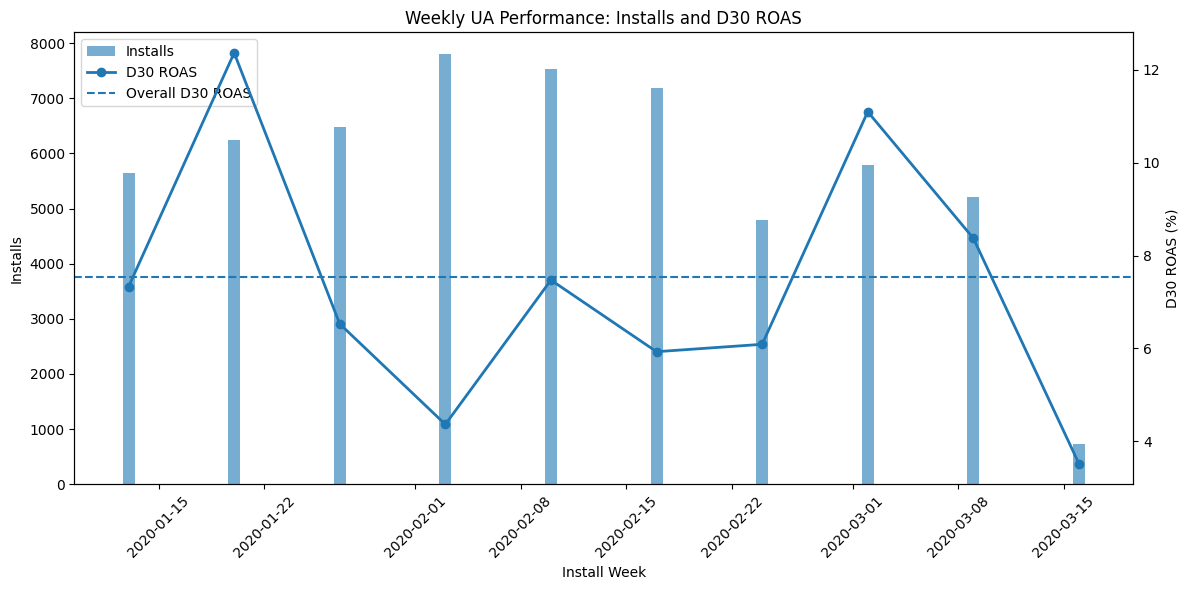

In [16]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(12, 6))

bars = ax1.bar(
    weekly_cohorts["cohort_week"],
    weekly_cohorts["installs"],
    alpha=0.6,
    label="Installs"
)

ax1.set_xlabel("Install Week")
ax1.set_ylabel("Installs")
ax1.tick_params(axis="x", rotation=45)


ax2 = ax1.twinx()

ax2.plot(
    weekly_cohorts["cohort_week"],
    weekly_cohorts["D30_ROAS"] * 100,
    marker="o",
    linewidth=2,
    label="D30 ROAS"
)

# Overall D30 ROAS benchmark
ax2.axhline(
    D30_ROAS * 100,
    linestyle="--",
    label="Overall D30 ROAS"
)

ax2.set_ylabel("D30 ROAS (%)")



plt.title(
    "Weekly UA Performance: Installs and D30 ROAS"
)


lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left"
)

plt.tight_layout()
plt.show()

Both January 20 and March 2 generated D30 ROAS above the overall benchmark while maintaining substantial acquisition volume, followed by March 9, January 13, and February 10.

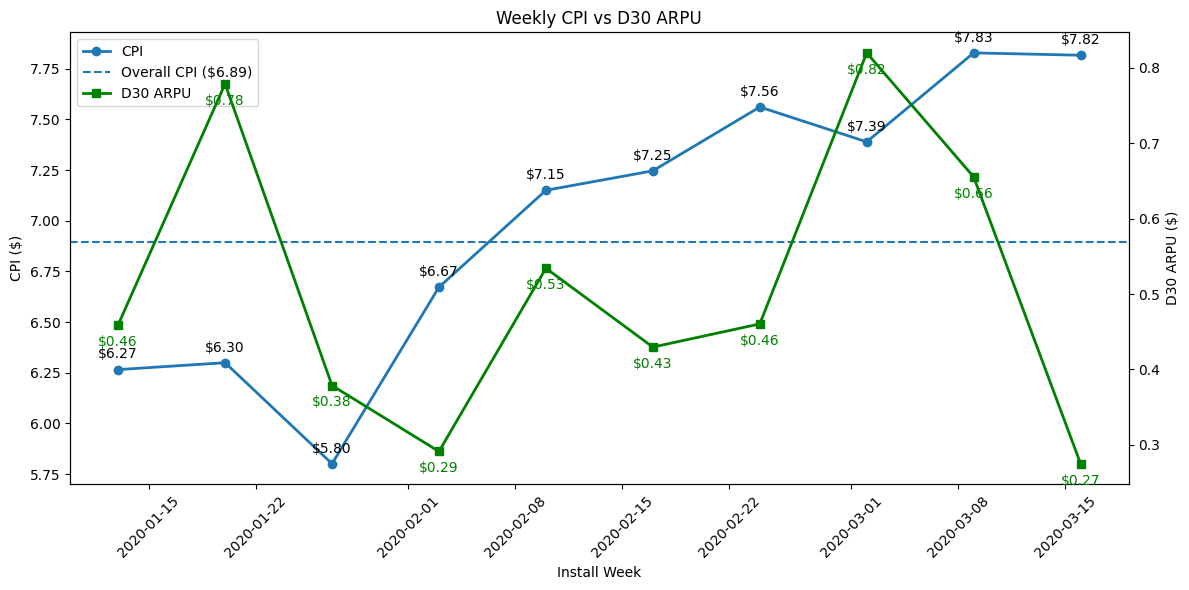

In [17]:
import matplotlib.pyplot as plt
CPI=spend/installs
fig, ax1 = plt.subplots(figsize=(12, 6))

# CPI line (left axis)
line1 = ax1.plot(
    weekly_cohorts["cohort_week"],
    weekly_cohorts["CPI"],
    marker="o",
    linewidth=2,
    label="CPI"
)

# Overall CPI benchmark
ax1.axhline(
    CPI,
    linestyle="--",
    label=f"Overall CPI (${CPI:.2f})"
)

# CPI labels
for x, y in zip(
    weekly_cohorts["cohort_week"],
    weekly_cohorts["CPI"]
):
    ax1.annotate(
        f"${y:.2f}",
        (x, y),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center"
    )

ax1.set_xlabel("Install Week")
ax1.set_ylabel("CPI ($)")

# ARPU line (right axis)
ax2 = ax1.twinx()

line2 = ax2.plot(
    weekly_cohorts["cohort_week"],
    weekly_cohorts["D30_ARPU"],
    marker="s",
    linewidth=2,
    color="green",
    label="D30 ARPU"
)

# ARPU labels
for x, y in zip(
    weekly_cohorts["cohort_week"],
    weekly_cohorts["D30_ARPU"]
):
    ax2.annotate(
        f"${y:.2f}",
        (x, y),
        xytext=(0, -15),
        textcoords="offset points",
        ha="center",
        color="green"
    )

ax2.set_ylabel("D30 ARPU ($)")

# Combined legend
lines = line1 + line2
labels = [line.get_label() for line in lines]

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper left")

ax1.set_title("Weekly CPI vs D30 ARPU")
ax1.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

January 20 combined a relatively low CPI (6.30) with high D30 ARPU (0.78), contributing to the highest D30 ROAS (12.36%).

March 2 achieved the second-highest D30 ARPU (0.82) despite a relatively high CPI (7.39), resulting in the second-highest D30 ROAS (11.10%).

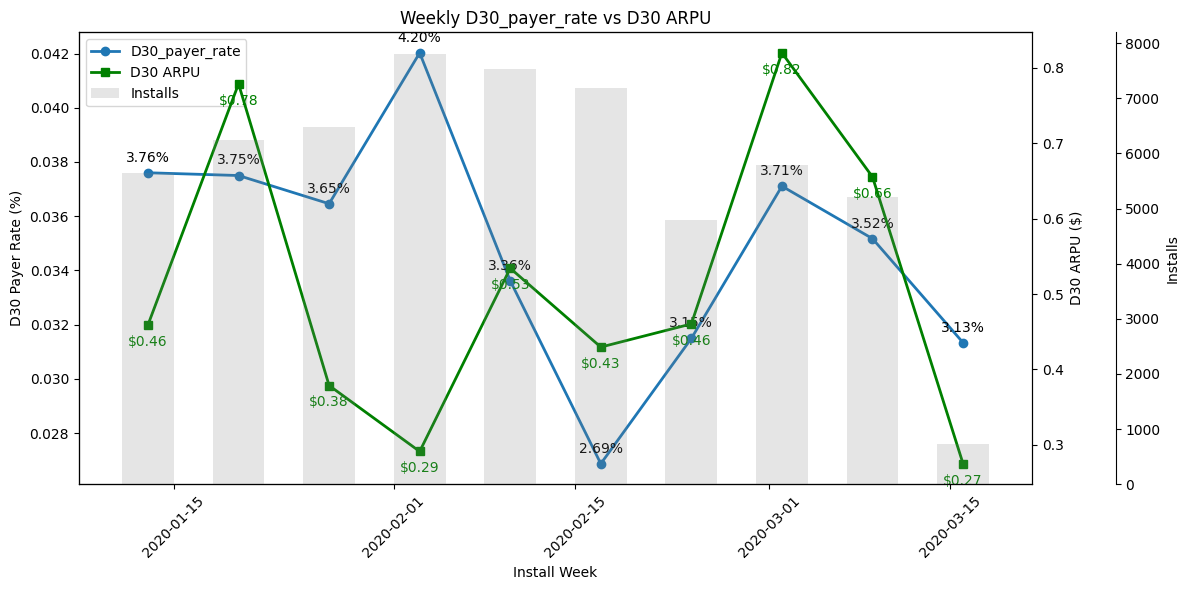

In [18]:
import matplotlib.pyplot as plt
CPI=spend/installs
fig, ax1 = plt.subplots(figsize=(12, 6))

# D30_payer_rate line (left axis)
line1 = ax1.plot(
    weekly_cohorts["cohort_week"],
    weekly_cohorts["D30_payer_rate"],
    marker="o",
    linewidth=2,
    label="D30_payer_rate"
)



# D30_payer_rate labels
for x, y in zip(
    weekly_cohorts["cohort_week"],
    weekly_cohorts["D30_payer_rate"]
):
    ax1.annotate(
        f"{y:.2%}",
        (x, y),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center"
    )

ax1.set_xlabel("Install Week")
ax1.set_ylabel("D30 Payer Rate (%)")

# ARPU line (right axis)
ax2 = ax1.twinx()

line2 = ax2.plot(
    weekly_cohorts["cohort_week"],
    weekly_cohorts["D30_ARPU"],
    marker="s",
    linewidth=2,
    color="green",
    label="D30 ARPU"
)

# Installs as bars (background)
ax3 = ax1.twinx()

bars = ax3.bar(
    weekly_cohorts["cohort_week"],
    weekly_cohorts["installs"],
    alpha=0.2,
    color="gray",
    label="Installs",
    width=4
)

ax3.set_ylabel("Installs")
ax3.spines["right"].set_position(("outward", 60))

# ARPU labels
for x, y in zip(
    weekly_cohorts["cohort_week"],
    weekly_cohorts["D30_ARPU"]
):
    ax2.annotate(
        f"${y:.2f}",
        (x, y),
        xytext=(0, -15),
        textcoords="offset points",
        ha="center",
        color="green"
    )

ax2.set_ylabel("D30 ARPU ($)")

# Combined legend
lines = line1 + line2
labels = [line.get_label() for line in lines]

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
handles3, labels3 = ax3.get_legend_handles_labels()

ax1.legend(
    handles1 + handles2 + handles3,
    labels1 + labels2 + labels3,
    loc="upper left"
)

ax1.set_title("Weekly D30_payer_rate vs D30 ARPU")
ax1.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

January 20 and March 2 combined high D30 ARPU with relatively high payer rates. The week of February 3 recorded the highest payer rate (4.20%), but D30 ARPU was relatively low at (0.29).

**Where did UA perform best?**

I next aggregated performance by country.

To reduce volatility from very small markets, I focused on countries with at least 500 installs.

Some of the strongest country-level results were:


In [19]:
country_perf = (
    df.groupby("country")
      .agg(
          installs=("Installs", "sum"),
          spend=("spend", "sum"),
          d30_revenue=("net_revenue_30", "sum"),
          pu_30=("pu_30_days", "sum"),
          day7=("day7", "sum")
      )
      .reset_index()
)

country_perf["CPI"] = (
    country_perf["spend"] / country_perf["installs"]
)

country_perf["D30_ROAS"] = (
    country_perf["d30_revenue"] / country_perf["spend"]
)

country_perf["D30_payer_rate"] = (
    country_perf["pu_30"] / country_perf["installs"]
)

country_perf["D7_retention"] = (
    country_perf["day7"] / country_perf["installs"]
)

country_perf["D30_ARPU"] = (
    country_perf["d30_revenue"] / country_perf["installs"]
)

# Remove countries with <500 installs from the ranking
country_perf_valid = country_perf[country_perf["installs"] > 500].copy()

# Show countries sorted by D30 ROAS
print(
    country_perf_valid
    .sort_values("D30_ROAS", ascending=False)
    .round(4)

)

   country  installs        spend  d30_revenue  pu_30    day7      CPI  D30_ROAS  D30_payer_rate  D7_retention  D30_ARPU
39      GR    1304.0    5492.4000       978.82   50.0   332.0   4.2120    0.1782          0.0383        0.2546    0.7506
86      RO    3944.0   12583.0243      1582.89  136.0  1340.0   3.1904    0.1258          0.0345        0.3398    0.4013
6       AU     875.0   13397.8057      1326.33   44.0   209.0  15.3118    0.0990          0.0503        0.2389    1.5158
34      GB    2666.0   22518.9300      2110.62  138.0   628.0   8.4467    0.0937          0.0518        0.2356    0.7917
97      US    9535.0  154301.6286     14113.78  633.0  2147.0  16.1827    0.0915          0.0664        0.2252    1.4802
57      LB    1047.0    4524.8700       372.57   24.0   283.0   4.3217    0.0823          0.0229        0.2703    0.3558
33      FR    2493.0   20752.5571      1428.25   96.0   477.0   8.3243    0.0688          0.0385        0.1913    0.5729
88      SE    1139.0    9860.237

Greece achieved the highest D30 ROAS among countries meeting the 500-install threshold, while Romania combined a relatively low CPI with strong D30 ROAS and retention at meaningful acquisition volume.

The US recorded a high D30 payer rate and the highest D30 ARPU among the countries analyzed. However, its high CPI contributed to a lower D30 ROAS than Greece and Romania.


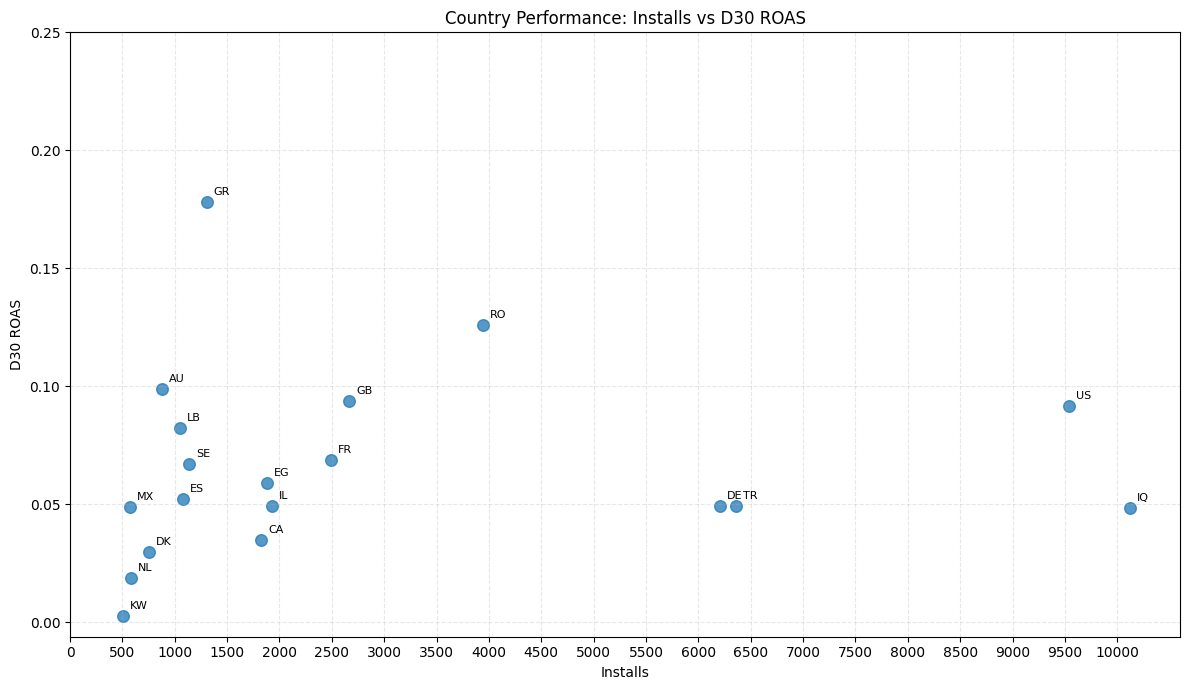

In [20]:
import matplotlib.pyplot as plt

plot_df = country_perf_valid.copy()

plt.figure(figsize=(12, 7))

plt.scatter(
    plot_df["installs"],
    plot_df["D30_ROAS"],
    alpha=0.75,
    s=70
)

# Add country labels
for _, row in plot_df.iterrows():
    plt.annotate(
        row["country"],
        (row["installs"], row["D30_ROAS"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Installs")
plt.ylabel("D30 ROAS")
plt.title("Country Performance: Installs vs D30 ROAS")
plt.xticks(range(0, 10001, 500))
plt.yticks(np.arange(0, 0.26, 0.05))
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

**When × Where did UA perform best?**

I next combined the cohort and country dimensions to identify which markets contributed to the strongest install cohorts.

To reduce volatility from very small cohort-country combinations, I focused on combinations with at least 200 installs.

The strongest meaningful cohort-country results were:


In [21]:
# Cohort × Country analysis

cohort_country = (
    df.groupby(["cohort_week", "country"])
      .agg(
          installs=("Installs", "sum"),
          spend=("spend", "sum"),
          d30_revenue=("net_revenue_30", "sum"),
          pu_30=("pu_30_days", "sum"),
          day7=("day7", "sum"),
          clicks=("clicks", "sum"),
          net_revenue=("net_revenue", "sum")
      )
      .reset_index()
)



# Calculate KPIs

cohort_country["CPI"] = (
    cohort_country["spend"] /
    cohort_country["installs"]
)

cohort_country["D30_ROAS"] = (
    cohort_country["d30_revenue"] /
    cohort_country["spend"]
)

cohort_country["D30_payer_rate"] = (
    cohort_country["pu_30"] /
    cohort_country["installs"]
)

cohort_country["D7_retention"] = (
    cohort_country["day7"] /
    cohort_country["installs"]
)

cohort_country["D30_ARPU"] = (
    cohort_country["d30_revenue"] / cohort_country["installs"]
)


# Keep meaningful cohort-country combinations

cohort_country_scaled = cohort_country[
    cohort_country["installs"] >= 200
].copy()

# Display
print(
    cohort_country_scaled[
        [
            "cohort_week",
            "country",
            "installs",
            "spend",
            "CPI",
            "D30_ROAS",
            "D30_payer_rate",
            "D7_retention",
            "D30_ARPU"
        ]
    ]
    .sort_values(
        ["cohort_week", "D30_ROAS"],
        ascending=[True, False]
    )
    .round(4)
)

    cohort_week country  installs    spend     CPI  D30_ROAS  D30_payer_rate  D7_retention  D30_ARPU
59   2020-01-13      RO     323.0   501.19  1.5517    0.4617          0.0526        0.3313    0.7164
27   2020-01-13      GB     265.0  2498.60  9.4287    0.3574          0.0717        0.2415    3.3703
35   2020-01-13      IQ    1101.0   202.21  0.1837    0.2796          0.0073        0.3188    0.0513
23   2020-01-13      EG     340.0   505.38  1.4864    0.2007          0.0088        0.1500    0.2983
64   2020-01-13      TR     436.0   898.19  2.0601    0.0676          0.0252        0.2087    0.1392
..          ...     ...       ...      ...     ...       ...             ...           ...       ...
574  2020-03-09      IQ     740.0   696.75  0.9416    0.0391          0.0041        0.2986    0.0368
555  2020-03-09      DE     364.0  3186.96  8.7554    0.0385          0.0522        0.2610    0.3374
560  2020-03-09      EG     215.0   697.67  3.2450    0.0351          0.0047        0.1256 

On January 13, the third-best week in terms of overall D30 ROAS, Romania and Great Britain achieved the highest ROAS among the countries listed.


Romania combined above-average D30 ARPU and payer rate with a relatively low CPI, while Great Britain also performed better than its average.


Iraq, on the other hand, achieved a high D30 ROAS despite a very low payer rate and D30 ARPU, suggesting that its results may have been driven by a small number of paying users.


On March 2, Romania again delivered strong results, achieving a D30 ROAS of 26.64% and demonstrating its potential to generate efficient returns across different weeks.


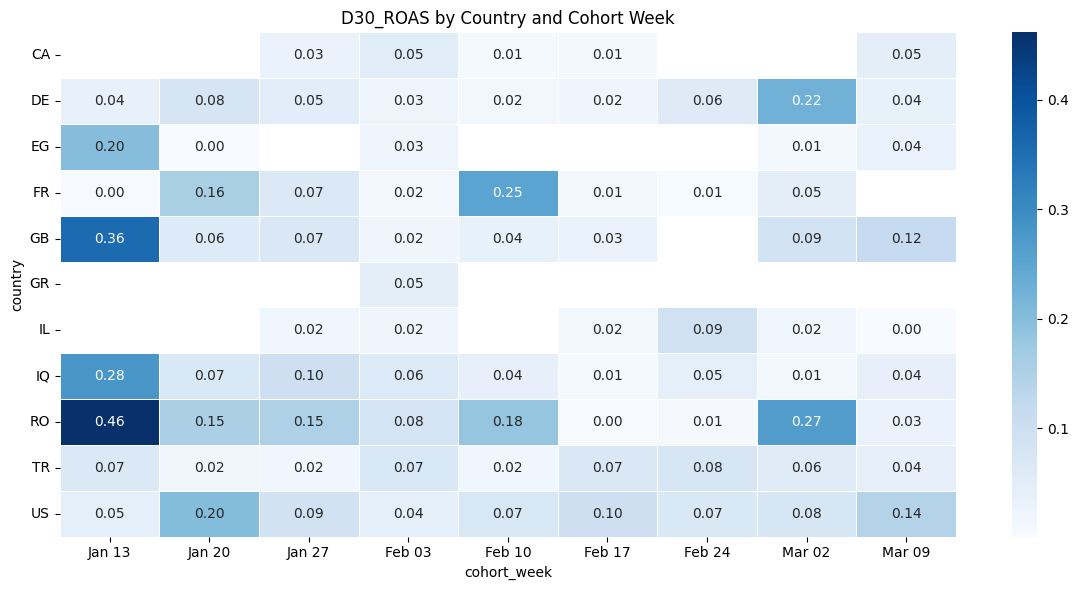

In [22]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

metric = "D30_ROAS"

# Create the heatmap matrix
heatmap_data = cohort_country_scaled.pivot_table(
    index="country",
    columns="cohort_week",
    values=metric,
)

# Sort dates chronologically
heatmap_data = heatmap_data.reindex(
    sorted(heatmap_data.columns), axis=1
)
heatmap_data.columns = [
    date.strftime("%b %d") for date in heatmap_data.columns
]
# Plot
plt.figure(figsize=(12, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    mask=heatmap_data.isna(),
    linewidths=0.5,
    cbar=True
)

plt.xlabel("cohort_week")
plt.ylabel("country")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.title(f"{metric} by Country and Cohort Week")
plt.setp(
    plt.gca().get_xticklabels(),
    rotation=0,
    ha="center",
    rotation_mode="anchor"
)
plt.tight_layout()
plt.show()


**When × Where × Platform**

I next combined cohort, country, and platform to identify which specific market-platform combinations contributed to the strongest UA performance

The strongest meaningful cohort-country-platform combinations were:


In [23]:

# Cohort × Country × Platform analysis

cohort_country = (
    df.groupby(["cohort_week", "country", "platform"])
      .agg(
          installs=("Installs", "sum"),
          spend=("spend", "sum"),
          d30_revenue=("net_revenue_30", "sum"),
          pu_30=("pu_30_days", "sum"),
          day7=("day7", "sum"),
          clicks=("clicks", "sum"),
          net_revenue=("net_revenue", "sum")
      )
      .reset_index()
)


# Calculate KPIs AFTER aggregation

cohort_country["CPI"] = (
    cohort_country["spend"] / cohort_country["installs"]
)

cohort_country["D30_ROAS"] = (
    cohort_country["d30_revenue"] / cohort_country["spend"]
)

cohort_country["D30_payer_rate"] = (
    cohort_country["pu_30"] / cohort_country["installs"]
)

cohort_country["D7_retention"] = (
    cohort_country["day7"] / cohort_country["installs"]
)

cohort_country["D30_ARPU"] = (
    cohort_country["d30_revenue"] / cohort_country["installs"]
)


# Keep meaningful combinations

cohort_country_scaled = cohort_country[
    cohort_country["installs"] >= 200
].copy()


# Display results
pd.set_option("display.max_rows", None)

print(
    cohort_country_scaled[
        [
            "cohort_week",
            "country",
            "platform",
            "installs",
            "spend",
            "CPI",
            "D30_ROAS",
            "D30_payer_rate",
            "D7_retention",
            "D30_ARPU",
            "d30_revenue"
        ]
    ]
    .sort_values(
        "D30_ROAS",ascending=False

    )
    .round(4).head(10)
)


    cohort_week country platform  installs       spend      CPI  D30_ROAS  D30_payer_rate  D7_retention  D30_ARPU  d30_revenue
81   2020-01-13      RO      iOS     323.0    501.1900   1.5517    0.4617          0.0526        0.3313    0.7164       231.39
689  2020-03-02      DE      iOS     253.0   2560.8900  10.1221    0.2974          0.0672        0.2411    3.0106       761.69
404  2020-02-10      FR      iOS     227.0   2663.0714  11.7316    0.2827          0.0529        0.2203    3.3165       752.85
172  2020-01-20      US      iOS     717.0  11575.9700  16.1450    0.2808          0.0711        0.2357    4.5333      3250.36
51   2020-01-13      IQ      iOS    1101.0    202.2100   0.1837    0.2796          0.0073        0.3188    0.0513        56.53
752  2020-03-02      RO      iOS     414.0   2275.5500   5.4965    0.2664          0.0411        0.3527    1.4645       606.30
31   2020-01-13      EG      iOS     340.0    505.3800   1.4864    0.2007          0.0088        0.1500    0.29

The analysis shows that the strongest country-week combinations in terms of D30 ROAS were frequently concentrated on iOS.


Romania continued to deliver strong D30 ROAS, achieving 46.17% on January 13 and 26.64% on March 2.


Germany recorded a D30 ROAS of 29.74% on March 2, higher than its overall ROAS that week, suggesting that Android performance may have contributed to the lower overall ROAS.


A similar pattern was observed in the US and France, where iOS achieved higher D30 ROAS than Android or the overall country-level performance.


Iraq and Romania recorded the reported results entirely on iOS during the observed weeks, with no Android data shown for these country-week combinations.


**Campaign-level analysis**

In [26]:

# Cohort × Country × Platform × Campaign

cohort_country_platform_campaign = (
    df.groupby(
        ["cohort_week", "country", "platform", "campaign_name"]
    )
    .agg(
        installs=("Installs", "sum"),
        spend=("spend", "sum"),
        d30_revenue=("net_revenue_30", "sum"),
        pu_30=("pu_30_days", "sum"),
        day7=("day7", "sum"),
        clicks=("clicks", "sum"),
        net_revenue=("net_revenue", "sum")
    )
    .reset_index()
)

# Calculate KPIs after aggregation

result = cohort_country_platform_campaign

result["CPI"] = result["spend"] / result["installs"]

result["D30_ROAS"] = (
    result["d30_revenue"] / result["spend"]
)

result["D30_payer_rate"] = (
    result["pu_30"] / result["installs"]
)

result["D7_retention"] = (
    result["day7"] / result["installs"]
)

result["D30_ARPU"] = (
    result["d30_revenue"] / result["installs"]
)

# Filter meaningful combinations

result_scaled = result[
    result["installs"] >= 200
].copy()

# Display all rows

print(
    result_scaled.sort_values(
        "D30_ROAS",ascending=False
    )
    .round(4)
    .head(10)
)


     cohort_week country platform campaign_name  installs      spend  d30_revenue  pu_30   day7  clicks  net_revenue      CPI  D30_ROAS  D30_payer_rate  D7_retention  D30_ARPU
263   2020-01-20      US      iOS        WW_New     226.0  3860.5900      3092.61   18.0   53.0     834      3598.94  17.0823    0.8011          0.0796        0.2345   13.6841
110   2020-01-13      RO      iOS        T3_New     323.0   501.1900       231.39   17.0  107.0    1072       239.07   1.5517    0.4617          0.0526        0.3313    0.7164
1073  2020-03-02      DE      iOS        T2_New     212.0  2079.4700       690.37   14.0   52.0     701       889.75   9.8088    0.3320          0.0660        0.2453    3.2565
612   2020-02-10      FR      iOS    Europe_New     227.0  2663.0714       752.85   12.0   50.0    1051       803.86  11.7316    0.2827          0.0529        0.2203    3.3165
74    2020-01-13      IQ      iOS        T3_New    1101.0   202.2100        56.53    8.0  351.0    3180        70.50   0

The US iOS WW_NEW campaign achieved the highest D30 ROAS (80%) and payer rate (7.96%), significantly outperforming the other campaigns. Romania’s T3_NEW campaign followed with a 46% ROAS, while Germany and France delivered lower ROAS despite similar payer rates.

**Conclusion**

Overall, strong UA performance was observed in the January 13, January 20, and March 2 cohorts, which generated D30 ROAS of 7%, 12.36%, and 11.10%, respectively, compared with the overall benchmark of 7.54%.

At the country level, Greece, Romania, Great Britain, the US, and Germany showed strong D30 ROAS among countries with at least 500 installs.

The deeper cohort × country × platform analysis showed that the strongest performance was concentrated in selected iOS combinations, particularly:

•	Jan 13 – Romania – iOS: 46.17% D30 ROAS

•	Mar 2 – Germany – iOS: 29.74% D30 ROAS

•	Jan 20 – US – iOS: 28.08% D30 ROAS
